# Alchemistry 2027 Antiviral Blind Challenge — tutorial

Predicting binding free energies for 54 compounds against the **dengue virus
serotype 2 NS2B-NS3 protease**.

This notebook walks end to end through a submission: getting the data, looking
at what you have been given, making a set of example
predictions, writing them in the required format, validating the file locally,
and submitting it.

**It does not run a free energy calculation.** It only shows you how to retrieve the test data programmatically and gives some advice on submission.

- Challenge Space: <https://huggingface.co/spaces/openadmet/alchemistry-2027-challenge>
- Dataset: <https://huggingface.co/datasets/openadmet/alchemistry-2027-antiviral-blind-challenge>

---

## Setup

```bash
pip install pandas numpy matplotlib rdkit huggingface_hub pyarrow
```


In [1]:
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from rdkit import Chem, RDLogger
from rdkit.Chem import Descriptors, Draw
from rdkit.Chem.Scaffolds import MurckoScaffold

RDLogger.DisableLog("rdApp.*")
pd.set_option("display.width", 140)


---
## 1. Get the data

Two files: the 54 test compounds, and one crystal structure of the protease
with a ligand bound.


In [2]:
from huggingface_hub import hf_hub_download

REPO = "openadmet/alchemistry-2027-antiviral-blind-challenge"

csv_path = hf_hub_download(REPO, "alchemistry-2027-challenge_TEST_BLINDED.csv",
                           repo_type="dataset")
pdb_path = hf_hub_download(REPO, "alchemistry-2027-challenge_reference_complex.pdb",
                           repo_type="dataset")

test = pd.read_csv(csv_path)
print(f"{len(test)} compounds, columns: {list(test.columns)}")
test.head()


/home/jenke/micromamba/envs/alchemistry-website/lib/python3.15/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


54 compounds, columns: ['Molecule_Name', 'CXSMILES (CDD Compatible)']


,Molecule_Name,CXSMILES (CDD Compatible)
0,A_001,CN1CC[C@@H](NC2=NC3=CC(C(=O)NC4=CC=C(C(C)(C)C)...
1,A_002,CCN1CC(NC2=NC3=CC(C(=O)NC4=CC=C(F)C=C4)=CC(Cl)...
2,A_003,CC(C)NC1=NC2=CC(C(=O)NC3=CC=C4CNCC4=C3)=CC=C2N1
3,A_004,CC1=CC=C(NC(=O)C2=CC(Cl)=C3NC(NCCN)=NC3=C2)C=C1C
4,A_005,O=C(NC1=CC=C2CN(CC(F)F)CC2=C1)C1=CC=C2NC(NC3CN...


The column names are exactly what the submission format
expects, so you can add your prediction columns to this dataframe and submit it
without renaming anything.

---
## 2. Explore the test set



Three separate panels rather than one chart: the properties are on different
scales, and putting them on a shared axis would be misleading.


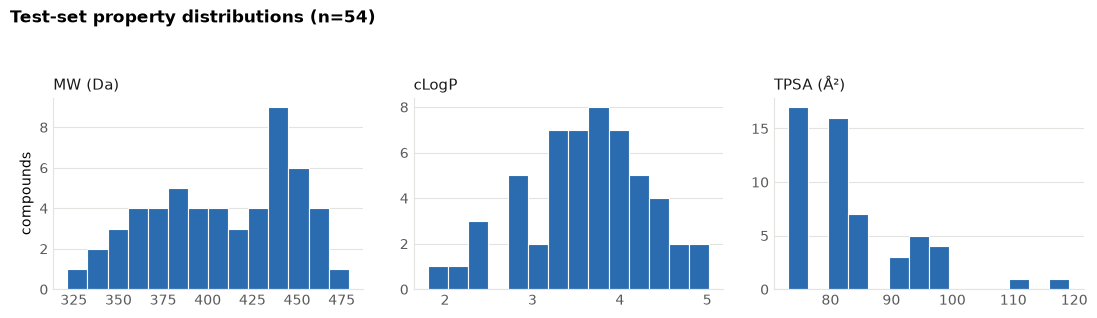

In [20]:
HUE, GRID, INK = "#2b6cb0", "#e3e3e0", "#5a5a5a"

test["mol"] = test["CXSMILES (CDD Compatible)"].map(Chem.MolFromSmiles)
assert test.mol.notna().all(), "some SMILES failed to parse"

test["MW"] = test.mol.map(Descriptors.MolWt)
test["cLogP"] = test.mol.map(Descriptors.MolLogP)
test["TPSA"] = test.mol.map(Descriptors.TPSA)
fig, axes = plt.subplots(1, 3, figsize=(11, 3.2))

for ax, col, unit in zip(axes, ["MW", "cLogP", "TPSA"],
                         ["Da", "", "\u00c5\u00b2"]):
    ax.hist(test[col], bins=14, color=HUE, edgecolor="white", linewidth=0.8)
    ax.set_title(f"{col}" + (f" ({unit})" if unit else ""), loc="left",
                 fontsize=10.5, color="#1a1a1a")
    ax.set_ylabel("compounds" if col == "MW" else "")
    ax.grid(axis="y", color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(length=0, colors=INK)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
    for s in ("left", "bottom"):
        ax.spines[s].set_color(GRID)
fig.suptitle(f"Test-set property distributions (n={len(test)})", x=0.005, ha="left",
             fontsize=12, weight="bold")
fig.tight_layout(rect=[0, 0, 1, 0.92])
plt.show()


### The series is composed of decorations on a single scaffold


15 distinct Bemis-Murcko scaffolds across 54 compounds
group sizes: [23, 10, 6, 2, 2, 2, 1, 1, 1, 1, 1, 1, 1, 1, 1]

dominant scaffold (23 compounds):
O=C(Nc1ccccc1)c1ccc2[nH]c(NC3CNC3)nc2c1


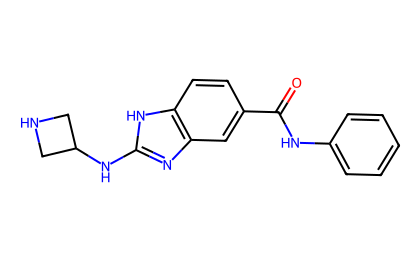

In [21]:
test["scaffold"] = test.mol.map(
    lambda m: MurckoScaffold.MurckoScaffoldSmiles(mol=m)
)
counts = test.scaffold.value_counts()

print(f"{len(counts)} distinct Bemis-Murcko scaffolds across {len(test)} compounds")
print(f"group sizes: {list(counts)}\n")
print(f"dominant scaffold ({counts.iloc[0]} compounds):\n{counts.index[0]}")
Draw.MolToImage(Chem.MolFromSmiles(counts.index[0]), size=(420, 260))


In [6]:
ambiguous = test[test.mol.map(lambda m: bool(m.GetStereoGroups()))]
print(f"{len(ambiguous)} of {len(test)} compounds carry an enhanced stereo group")
ambiguous[["Molecule_Name", "CXSMILES (CDD Compatible)"]]


3 of 54 compounds carry an enhanced stereo group


,Molecule_Name,CXSMILES (CDD Compatible)
21,A_022,CC1=CC=C(NC(=O)C2=CC(Cl)=C3NC(N[C@H]4CCNC4)=NC...
40,A_041,O=C(NC1=CC=CC=C1)C1=CC(Cl)=C2NC(N[C@H]3CCNC3)=...
52,A_053,O=C(NC1=CC=C2CNCC2=C1)C1=CC(Cl)=C2NC(N[C@H]3CC...


There are a few strategies in dealing with these racemic measurements: it's up to you to decide what you want to do.

---
## 3. The reference structure

A crystal structure of the NS2B-NS3 protease with one of the series bound, so
you have an experimentally determined binding mode to build on rather than
having to dock blind.


In [22]:
pdb = Path(pdb_path).read_text().splitlines()

protein = {}
for line in pdb:
    if line.startswith("ATOM"):
        protein.setdefault(line[21], set()).add(int(line[22:26]))

for chain, residues in sorted(protein.items()):
    numbers = sorted(residues)
    gaps = [(a, b) for a, b in zip(numbers, numbers[1:]) if b - a > 1]
    print(f"chain {chain}: {len(numbers):3d} residues, {min(numbers)}-{max(numbers)}"
          f"{'  GAPS ' + str(gaps) if gaps else ''}")



chain A:  38 residues, 50-87
chain B: 151 residues, 17-172  GAPS [(27, 33)]


---
## 4. Example predictions

> ### ⚠️ This is not a method
> 
> What follows ranks the compounds by **molecular weight**. It involves no
> structure, no physics and no fitting. It exists so the rest of the notebook
> has something to put in a file.
> 
> We are using MW as a baseline in this challenge: hopefully your method outperforms it.


In [23]:
# Heavier -> predicted more potent.
DG_WEAKEST, DG_STRONGEST = -5.0, -8.0

rank = test.MW.rank(pct=True)
test["dG_pred"] = DG_WEAKEST + rank * (DG_STRONGEST - DG_WEAKEST)

# A real submission should quote a real uncertainty. 
test["dG_unc"] = 2.0

test[["Molecule_Name", "MW", "dG_pred", "dG_unc"]].head()


,Molecule_Name,MW,dG_pred,dG_unc
0,A_001,443.954,-7.361111,2.0
1,A_002,387.846,-6.055556,2.0
2,A_003,335.411,-5.111111,2.0
3,A_004,357.845,-5.555556,2.0
4,A_005,412.444,-6.555556,2.0


---
## 5. Build the submission file

One row per compound, four columns, exact names:

| column | what |
|---|---|
| `Molecule_Name` | the identifier, straight from the test set |
| `CXSMILES (CDD Compatible)` | the SMILES, straight from the test set |
| `denv2_ns2b_ns3_potency_predicted` | your binding free energy |
| `denv2_ns2b_ns3_potency_predicted_uncertainty` | its uncertainty |

⚠️ **Both values must be in kcal/mol**, and binding free energies are negative.
Units are the most common way to produce a technically valid submission that
scores poorly.

The uncertainty column is required. A flat value is acceptable if your method has no
per-compound error estimate.


In [24]:
submission = pd.DataFrame({
    "Molecule_Name": test.Molecule_Name,
    "CXSMILES (CDD Compatible)": test["CXSMILES (CDD Compatible)"],
    "denv2_ns2b_ns3_potency_predicted": test.dG_pred.round(4),
    "denv2_ns2b_ns3_potency_predicted_uncertainty": test.dG_unc.round(4),
})

out = Path("example_submission.csv")
submission.to_csv(out, index=False)
print(f"wrote {out} ({len(submission)} rows)")
submission.head()


wrote example_submission.csv (54 rows)


,Molecule_Name,CXSMILES (CDD Compatible),denv2_ns2b_ns3_potency_predicted,denv2_ns2b_ns3_potency_predicted_uncertainty
0,A_001,CN1CC[C@@H](NC2=NC3=CC(C(=O)NC4=CC=C(C(C)(C)C)...,-7.3611,2.0
1,A_002,CCN1CC(NC2=NC3=CC(C(=O)NC4=CC=C(F)C=C4)=CC(Cl)...,-6.0556,2.0
2,A_003,CC(C)NC1=NC2=CC(C(=O)NC3=CC=C4CNCC4=C3)=CC=C2N1,-5.1111,2.0
3,A_004,CC1=CC=C(NC(=O)C2=CC(Cl)=C3NC(NCCN)=NC3=C2)C=C1C,-5.5556,2.0
4,A_005,O=C(NC1=CC=C2CN(CC(F)F)CC2=C1)C1=CC=C2NC(NC3CN...,-6.5556,2.0


---
## 6. Relative methods: the perturbation network

If your method is **edge-based** (FEP, TI, NEQ) you also submit the network you
ran: one row per perturbation, with its relative free energy and uncertainty.

| column | what |
|---|---|
| `Molecule_Name_A` | one end of the edge |
| `Molecule_Name_B` | the other end |
| `denv2_ns2b_ns3_potency_predicted_ddg` | the ΔΔG for that edge |
| `denv2_ns2b_ns3_potency_predicted_ddg_uncertainty` | its uncertainty |

⚠️ **Also kcal/mol.** Sign convention: the ΔΔG of going from A to B,
so negative means B is predicted to bind more tightly than A.

Absolute methods (ABFE), machine learning and other approaches have no network
and are not asked for one. This file is **required** if you pick a relative method class — the Space
rejects the submission without it.

You still submit per-compound ΔG values in the main file. The form asks
which estimator you used for estimating absolute values.

The cell below writes a toy three-edge file purely to show the shape. A real
network connects all 54 compounds.


In [25]:
names = submission.Molecule_Name.tolist()
dg = dict(zip(submission.Molecule_Name,
              submission.denv2_ns2b_ns3_potency_predicted))

edges = [(names[i], names[i + 1]) for i in range(3)]
network = pd.DataFrame({
    "Molecule_Name_A": [a for a, _ in edges],
    "Molecule_Name_B": [b for _, b in edges],
    "denv2_ns2b_ns3_potency_predicted_ddg":
        [round(dg[b] - dg[a], 4) for a, b in edges],
    "denv2_ns2b_ns3_potency_predicted_ddg_uncertainty": 0.3,
})
network.to_csv("example_network.csv", index=False)
network


,Molecule_Name_A,Molecule_Name_B,denv2_ns2b_ns3_potency_predicted_ddg,denv2_ns2b_ns3_potency_predicted_ddg_uncertainty
0,A_001,A_002,1.3055,0.3
1,A_002,A_003,0.9445,0.3
2,A_003,A_004,-0.4445,0.3


---
## 7. Submit

Go to the **Submit** tab of the
[challenge Space](https://huggingface.co/spaces/openadmet/alchemistry-2027-challenge).

Although other OpenADMET challenges allowed programmatic submissions, it is not the supported route for this challenge and we
are not documenting it. Please submit through the web form as it is the only path
we test.

**Identity.** Submissions are made under your Hugging Face username. If you would
rather not be identified on the public board, tick *Submit anonymously* and give
an alias to display instead. Your name and contact details are never shown publicly.

**Method class.** This is the first choice on the form and it decides what else
you are asked for:

| class | also asked for |
|---|---|
| Relative / edge-based (FEP, TI, NEQ) | the network file from §6, and an optional note on how the network was designed and how per-compound potencies were estimated from it |
| Absolute (ABFE, etc.) | nothing beyond the standard physics questions |
| Machine learning (QSAR, GNN, etc.) | a single free-text methods box *instead of* the physics questions |
| Other / hybrid | the standard physics questions |

**Method details.** We ask for a variety of required and optional details of your methods. 
This way we can analyze what methods work best when the challenge is over. Short descriptions
of your methods are enough, you do not need to write an extensive methods section!


**Files.** The predictions CSV is required. A zip of predicted poses (one PDB or
mmCIF per compound, fully prepared and protonated) is requested but optional —
poses are not scored, and a problem with that file will never reject your
predictions.

### After you submit

The leaderboard regenerates every 15 minutes, so allow a little time before you
look for your entry. Four things to expect:

- **Only your most recent valid submission counts.** A new submission replaces
  your previous standing rather than adding a second row.
- **You can submit again after 48 hours.** The clock starts only on an
  accepted submission — a file rejected for a formatting problem does not use
  up a window.
- **Relative submissions show `N/A` for ST-RAE and MAE.** Ranking metrics are unaffected, and the
  leaderboard ranks on Kendall's τ anyway.
- **Machine-learning submissions appear on their own leaderboard**, not ranked
  against the physics-based methods.

The live board is scored on a subset of the compounds, the interim leaderboard uses larger subset and only the final
leaderboard uses the full set, so the numbers are not comparable between them. A
good live score is encouraging and useful in determining you're on the right track.

Questions are welcome in **#😷alchemistry-2027-challenge** on the
[OpenADMET Discord](https://discord.gg/U5XtzEVZ6).
